# Red Neuronal Perceptrón Multicapa (MLP) con scikit-learn

Luis Angel Flores Espinosa

Deep Learning


# 1. Fundamentos teóricos del MLP

Un **Perceptrón Multicapa (MLP)** es una red neuronal *feed-forward* (la información fluye solo de la entrada a la salida) formada por capas de neuronas totalmente conectadas:

- **Capa de entrada:** recibe los atributos del patrón (una neurona por atributo).
- **Capas ocultas:** cada neurona calcula una suma ponderada de sus entradas y le aplica una **función de activación no lineal**.
- **Capa de salida:** entrega la predicción (una neurona por clase).

Las capas ocultas con activación no lineal permiten resolver problemas **no linealmente separables** (el perceptrón simple no puede).

**Aprendizaje:**
1. *Forward pass*: se calcula la salida de la red.
2. Se mide el error con una **función de pérdida**.
3. **Backpropagation**: se calcula el gradiente de la pérdida respecto a cada peso (regla de la cadena).
4. Un **optimizador** (SGD, Adam) actualiza los pesos. Se repite por varias **épocas**.

**Activaciones comunes:** sigmoide $\sigma(z)=\frac{1}{1+e^{-z}}$, tanh, ReLU $\max(0,z)$ y softmax (salida multiclase).

Los MLP son sensibles a la escala de los atributos, por eso se **escalan** los datos antes de entrenar.

# 2. Modelo matemático del MLP

**Neurona $j$ de la capa $l$:**

$$z_j^{(l)}=\sum_i w_{ji}^{(l)}\,a_i^{(l-1)}+b_j^{(l)}\qquad a_j^{(l)}=f\left(z_j^{(l)}\right)$$

**Forma matricial (con $\mathbf{a}^{(0)}=\mathbf{x}$):**

$$\mathbf{z}^{(l)}=W^{(l)}\mathbf{a}^{(l-1)}+\mathbf{b}^{(l)}\qquad \mathbf{a}^{(l)}=f\left(\mathbf{z}^{(l)}\right)$$

**Salida softmax** para $K$ clases:

$$\hat{y}_k=\frac{e^{z_k^{(L)}}}{\sum_{j=1}^{K}e^{z_j^{(L)}}}$$

**Pérdida** (entropía cruzada + regularización L2 con parámetro $\alpha$):

$$J=-\frac{1}{N}\sum_{n=1}^{N}\sum_{k=1}^{K}y_k^{(n)}\ln\hat{y}_k^{(n)}+\frac{\alpha}{2N}\sum_{l}\lVert W^{(l)}\rVert^2$$

**Backpropagation:**

$$\boldsymbol{\delta}^{(L)}=\hat{\mathbf{y}}-\mathbf{y}\qquad
\boldsymbol{\delta}^{(l)}=\left(W^{(l+1)}\right)^{\top}\boldsymbol{\delta}^{(l+1)}\odot f'\left(\mathbf{z}^{(l)}\right)$$

$$\frac{\partial J}{\partial W^{(l)}}=\boldsymbol{\delta}^{(l)}\left(\mathbf{a}^{(l-1)}\right)^{\top}\qquad \frac{\partial J}{\partial \mathbf{b}^{(l)}}=\boldsymbol{\delta}^{(l)}$$

**Actualización de pesos** (descenso del gradiente, tasa de aprendizaje $\eta$):

$$W^{(l)}\leftarrow W^{(l)}-\eta\frac{\partial J}{\partial W^{(l)}}\qquad \mathbf{b}^{(l)}\leftarrow \mathbf{b}^{(l)}-\eta\frac{\partial J}{\partial \mathbf{b}^{(l)}}$$

**Arquitectura para Iris:** 4 entradas → 10 neuronas (ReLU) → 10 neuronas (ReLU) → 3 salidas (softmax).

# 3. Pipeline de Machine Learning

In [ ]:
import numpy as np  # Importa NumPy para cálculo numérico
import pandas as pd  # Importa pandas para manejar datos tabulares
import matplotlib.pyplot as plt  # Importa matplotlib para graficar
from sklearn.model_selection import train_test_split  # Importa la función para dividir en train/test
from sklearn.preprocessing import StandardScaler  # Importa el escalador (estandarización)
from sklearn.neural_network import MLPClassifier  # Importa el Perceptrón Multicapa
from sklearn.metrics import accuracy_score  # Importa la métrica accuracy
from sklearn.metrics import confusion_matrix  # Importa el cálculo de la matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay  # Importa el graficador de la matriz de confusión

## 3.1 Selección de los patrones de entrenamiento (Dataset)

**Iris** contiene **150 muestras** de flores de 3 especies (*Iris-setosa*, *Iris-versicolor*, *Iris-virginica*), 50 por especie. Cada muestra tiene 4 atributos en cm: largo y ancho del sépalo (`sepal-length`, `sepal-width`) y largo y ancho del pétalo (`petal-length`, `petal-width`). El CSV no trae encabezados, por eso se asignan los nombres al cargarlo.

In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.csv"  # URL del archivo CSV del dataset
columnas = ["sepal-length", "sepal-width", "petal-length", "petal-width", "class"]  # Nombres de las 5 columnas
df = pd.read_csv(url, header=None, names=columnas)  # Carga el CSV (sin encabezado) en un DataFrame
print("Dimensiones:", df.shape)  # Muestra (filas, columnas)
print(df["class"].value_counts())  # Cuenta las muestras de cada clase
df.head()  # Muestra las primeras 5 filas

Dimensiones: (150, 5)
class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,sepal-length,sepal-width,petal-length,petal-width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
df.describe()  # Estadísticos descriptivos (media, desv. est., mín, máx, cuartiles) de cada atributo

,sepal-length,sepal-width,petal-length,petal-width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Scatter plot

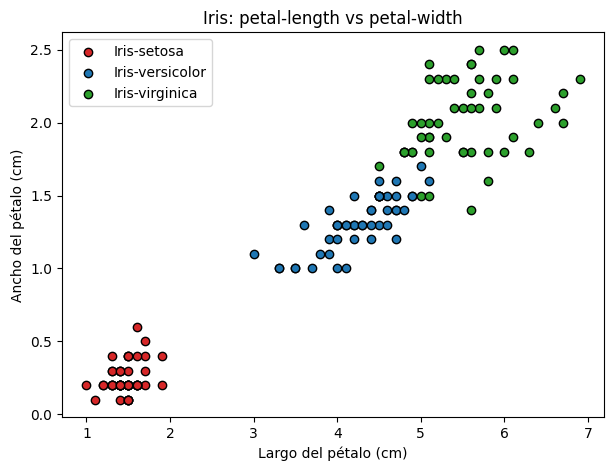

In [ ]:
plt.figure(figsize=(7, 5))  # Crea una figura de 7x5 pulgadas
colores = {"Iris-setosa": "tab:red", "Iris-versicolor": "tab:blue", "Iris-virginica": "tab:green"}  # Color de cada especie
for especie, color in colores.items():  # Recorre cada especie con su color
    sub = df[df["class"] == especie]  # Filtra las filas de la especie actual
    plt.scatter(sub["petal-length"], sub["petal-width"], c=color, edgecolor="k", label=especie)  # Dibuja sus puntos (X: largo, Y: ancho del pétalo)
plt.xlabel("Largo del pétalo (cm)")  # Etiqueta del eje X
plt.ylabel("Ancho del pétalo (cm)")  # Etiqueta del eje Y
plt.title("Iris: petal-length vs petal-width")  # Título del gráfico
plt.legend()  # Muestra la leyenda con las especies
plt.show()  # Muestra el gráfico

*Setosa* se separa claramente de las otras dos; *versicolor* y *virginica* se solapan parcialmente, por lo que se necesita una frontera de decisión no lineal.

## 3.2 Preprocesamiento

### 3.2.1 Splitting
Se divide el dataset en **entrenamiento (70 %)** para ajustar los pesos y **prueba (30 %)** para evaluar la generalización con datos no vistos. Con `stratify=y` se conserva la proporción de clases en ambos conjuntos.

In [ ]:
X = df.drop(columns=["class"]).values  # X: matriz con los 4 atributos (todas las columnas menos la clase)
y = df["class"].values  # y: vector con la especie de cada muestra
X_train, X_test, y_train, y_test = train_test_split(  # Divide los datos en entrenamiento y prueba
    X, y,  # Atributos y etiquetas a dividir
    test_size=0.30,  # 30 % de las muestras para prueba
    random_state=42,  # Semilla para que la división sea reproducible
    stratify=y  # Mantiene la proporción de clases en ambos conjuntos
)  # Cierra la llamada a train_test_split
print("Entrenamiento:", X_train.shape[0], "muestras")  # Cantidad de muestras de entrenamiento
print("Prueba:", X_test.shape[0], "muestras")  # Cantidad de muestras de prueba

Entrenamiento: 105 muestras
Prueba: 45 muestras


### 3.2.2 Scaling
Se estandarizan los atributos (*z-score*): $x'=\frac{x-\mu}{\sigma}$, quedando con media 0 y desviación 1. $\mu$ y $\sigma$ se calculan **solo con el conjunto de entrenamiento** para evitar *data leakage*, y se aplican luego a ambos conjuntos.

In [ ]:
scaler = StandardScaler()  # Crea el escalador de estandarización
scaler.fit(X_train)  # Calcula media y desviación estándar usando SOLO los datos de entrenamiento
X_train_s = scaler.transform(X_train)  # Escala el conjunto de entrenamiento: (x - media) / desviación
X_test_s = scaler.transform(X_test)  # Escala el conjunto de prueba con los mismos parámetros del entrenamiento
print("Media entrenamiento escalado:", X_train_s.mean(axis=0).round(3))  # Verifica que las medias sean ≈ 0
print("Desv. est. entrenamiento escalado:", X_train_s.std(axis=0).round(3))  # Verifica que las desviaciones sean ≈ 1

Media entrenamiento escalado: [ 0. -0. -0.  0.]
Desv. est. entrenamiento escalado: [1. 1. 1. 1.]


## 3.3 Selección del modelo y entrenamiento
Se usa `MLPClassifier` con 2 capas ocultas de 10 neuronas, activación ReLU y optimizador Adam. La capa de salida usa softmax y la pérdida es entropía cruzada.

In [ ]:
mlp = MLPClassifier(  # Crea el modelo MLP
    hidden_layer_sizes=(10, 10),  # Dos capas ocultas de 10 neuronas cada una
    activation="relu",  # Función de activación de las capas ocultas
    solver="adam",  # Algoritmo de optimización de los pesos
    alpha=0.0001,  # Coeficiente de regularización L2
    learning_rate_init=0.01,  # Tasa de aprendizaje inicial
    max_iter=500,  # Número máximo de épocas
    random_state=42  # Semilla para la inicialización de los pesos
)  # Cierra la creación del modelo
mlp.fit(X_train_s, y_train)  # Entrena la red con los datos de entrenamiento escalados
print("Épocas realizadas:", mlp.n_iter_)  # Muestra cuántas épocas se ejecutaron
print("Pérdida final:", round(mlp.loss_, 4))  # Muestra el valor final de la función de pérdida

Épocas realizadas: 211
Pérdida final: 0.0104


## 3.4 Evaluación del modelo
- **Accuracy** = predicciones correctas / total de predicciones.
- **Matriz de confusión**: la fila es la clase real y la columna la predicha; la diagonal contiene los aciertos.

In [ ]:
y_pred_train = mlp.predict(X_train_s)  # Predice las clases del conjunto de entrenamiento
y_pred_test = mlp.predict(X_test_s)  # Predice las clases del conjunto de prueba
print("Accuracy entrenamiento:", round(accuracy_score(y_train, y_pred_train), 4))  # Accuracy en entrenamiento
print("Accuracy prueba:", round(accuracy_score(y_test, y_pred_test), 4))  # Accuracy en prueba

Accuracy entrenamiento: 1.0
Accuracy prueba: 0.9111


[[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]


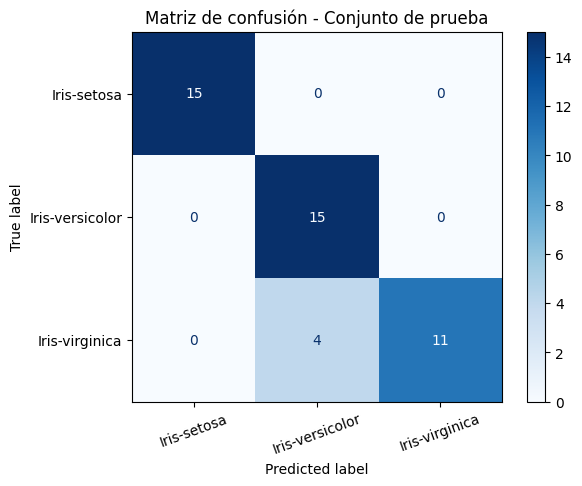

In [ ]:
cm = confusion_matrix(y_test, y_pred_test, labels=mlp.classes_)  # Calcula la matriz de confusión sobre el conjunto de prueba
print(cm)  # Imprime la matriz como arreglo numérico
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=mlp.classes_)  # Prepara el gráfico de la matriz
disp.plot(cmap="Blues", xticks_rotation=20)  # Dibuja la matriz con escala de azules
plt.title("Matriz de confusión - Conjunto de prueba")  # Título del gráfico
plt.show()  # Muestra el gráfico